# 02 — Exploratory Data Analysis (EDA): Wine Quality Dataset

## 1. Deskripsi

Notebook ini bertujuan melakukan analisis eksploratif terhadap dataset Wine Quality yang telah melalui tahap data preparation. Analisis dilakukan untuk memahami karakteristik fisikokimia wine, distribusi nilai quality, perbedaan jenis wine, serta hubungan antarvariabel.

## 2. Tujuan

1. Memahami karakteristik statistik setiap variabel.
2. Menganalisis distribusi nilai quality dan jenis wine.
3. Mengidentifikasi pola distribusi dan potensi outlier pada fitur numerik.
4. Menganalisis hubungan antarvariabel melalui korelasi.
5. Menentukan temuan awal yang dapat digunakan sebagai dasar eksperimen Machine Learning.

## 3. Dataset

Dataset yang digunakan adalah `winequality_cleaned.csv`, hasil tahap data preparation yang menggabungkan red wine dan white wine.

Dataset memiliki 5.320 baris dan 13 kolom, termasuk variabel `quality` dan `wine_type`.

## 4. Tahapan Analisis

Analisis meliputi statistik deskriptif, distribusi variabel, visualisasi fitur numerik, analisis outlier, dan korelasi antarvariabel.

## 5. Output

Hasil notebook ini berupa ringkasan statistik, visualisasi, dan interpretasi pola data yang digunakan untuk mendukung perancangan eksperimen Machine Learning.

In [1]:

# 1. Import library

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

# 2. Menentukan lokasi dataset
filename = "winequality_cleaned.csv"

possible_paths = [
    Path.cwd() / "data" / "processed" / filename,
    Path.cwd().parent / "data" / "processed" / filename,
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"{filename} tidak ditemukan. "
        "Periksa lokasi folder data/processed."
    )

# 3. Membaca dataset hasil cleaning
df = pd.read_csv(DATA_PATH)

print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset:", df.shape)

display(df.head())


Lokasi dataset: d:\MachineLearning\Wine\data\processed\winequality_cleaned.csv
Ukuran dataset: (5320, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [2]:

# 2. Statistik deskriptif dataset

# Memisahkan fitur numerik dan variabel target
feature_cols = [
    col for col in df.columns
    if col not in ["quality", "wine_type"]
]

print("Statistik deskriptif seluruh fitur:")
display(df[feature_cols].describe().T)

print("\nStatistik deskriptif target quality:")
display(df[["quality"]].describe().T)

print("\nDistribusi label wine_type:")
display(
    df["wine_type"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Red wine", 1: "White wine"})
    .to_frame("jumlah")
)


Statistik deskriptif seluruh fitur:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free sulfur dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total sulfur dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000



Statistik deskriptif target quality:


,count,mean,std,min,25%,50%,75%,max
quality,5320.0,5.795677,0.879772,3.0,5.0,6.0,6.0,9.0



Distribusi label wine_type:


,jumlah
wine_type,
Red wine,1359
White wine,3961


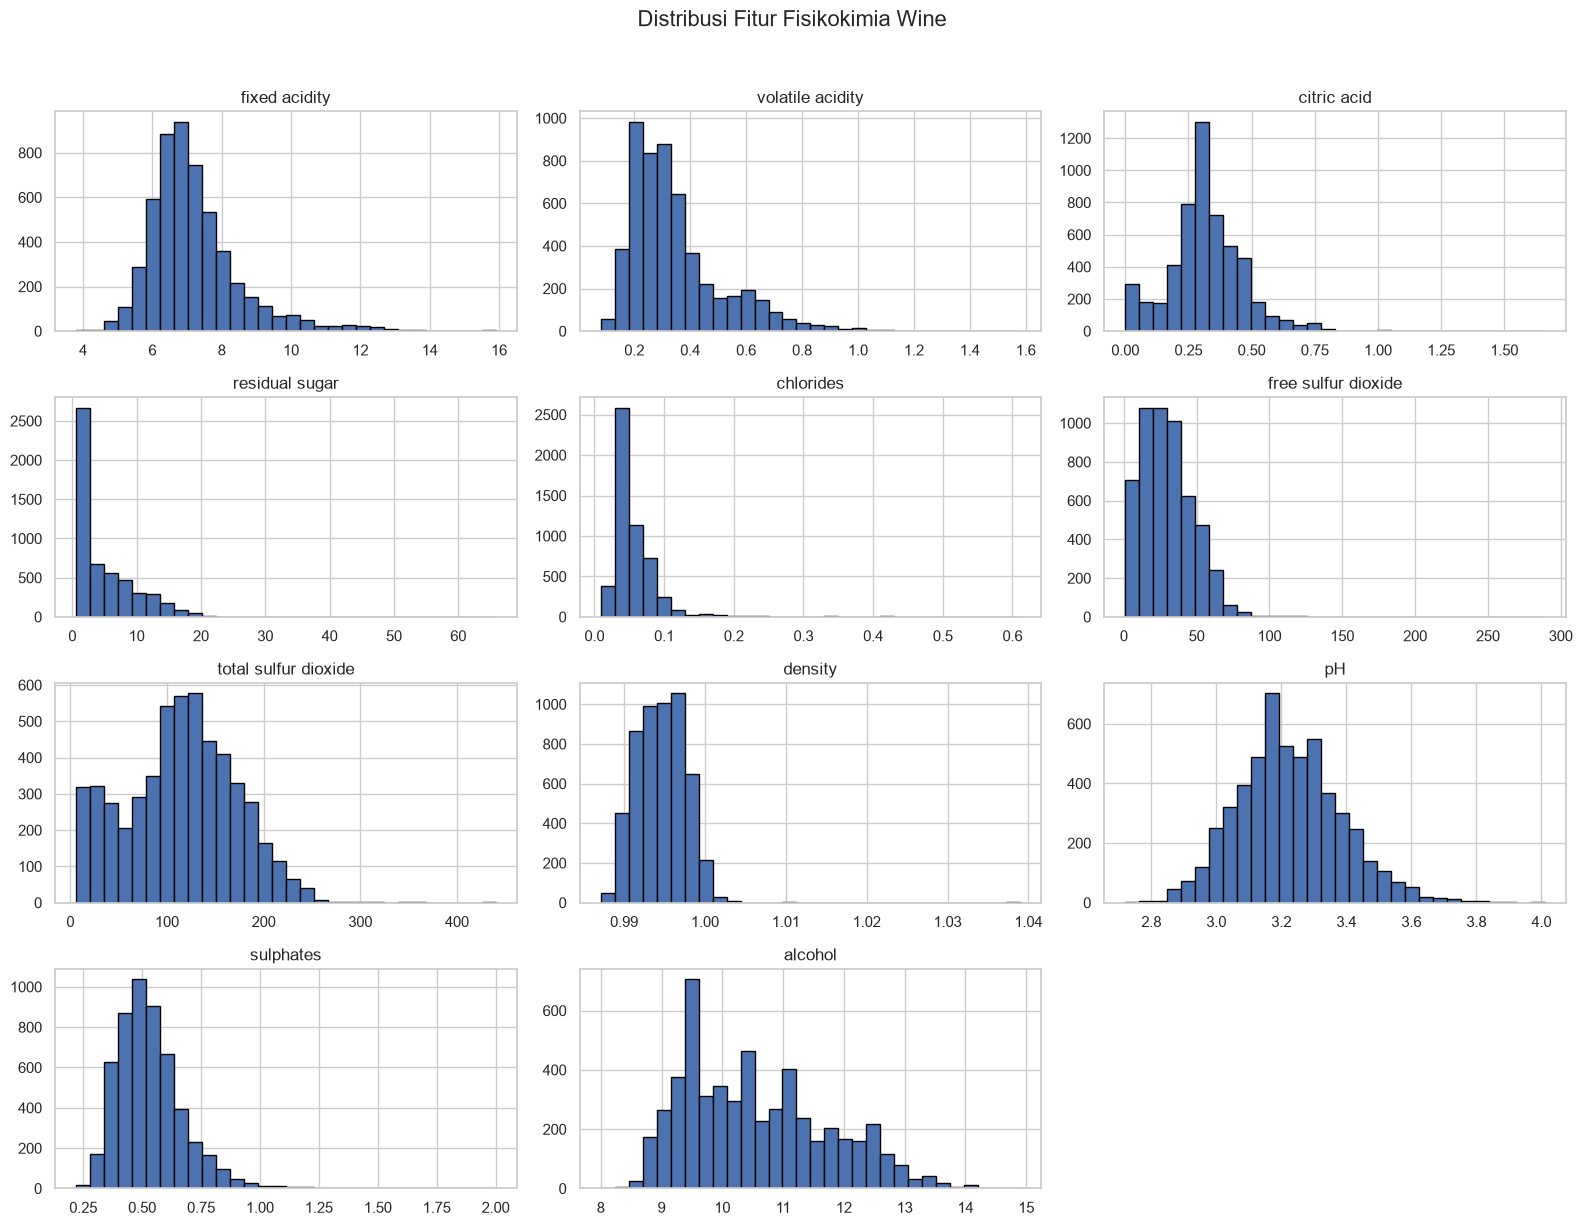

In [3]:

# 3. Distribusi fitur fisikokimia

feature_cols = [
    col for col in df.columns
    if col not in ["quality", "wine_type"]
]

df[feature_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribusi Fitur Fisikokimia Wine",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


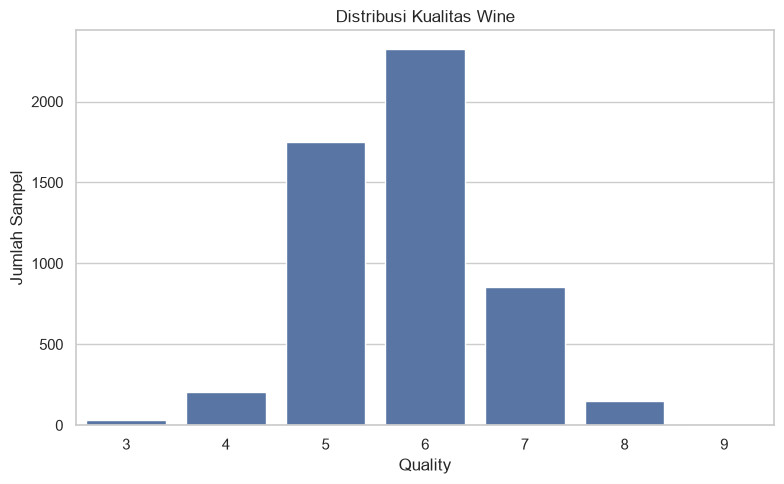

,jumlah
quality,
3,30
4,206
5,1752
6,2323
7,856
8,148
9,5


In [4]:
# 4. Distribusi target quality

quality_counts = df["quality"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=quality_counts.index,
    y=quality_counts.values
)

plt.title("Distribusi Kualitas Wine")
plt.xlabel("Quality")
plt.ylabel("Jumlah Sampel")
plt.tight_layout()
plt.show()

display(
    quality_counts
    .rename("jumlah")
    .to_frame()
)

In [5]:
# 5. Perbandingan karakteristik red wine dan white wine

feature_cols = [
    col for col in df.columns
    if col not in ["quality", "wine_type"]
]

wine_type_comparison = (
    df.groupby("wine_type")[feature_cols]
    .mean()
    .T
    .rename(columns={
        0: "Red wine",
        1: "White wine"
    })
)

wine_type_comparison["selisih_absolut"] = (
    wine_type_comparison["Red wine"]
    - wine_type_comparison["White wine"]
).abs()

display(
    wine_type_comparison.sort_values(
        "selisih_absolut",
        ascending=False
    ).round(3)
)

wine_type,Red wine,White wine,selisih_absolut
total sulfur dioxide,46.826,137.194,90.368
free sulfur dioxide,15.893,34.889,18.996
residual sugar,2.523,5.915,3.391
fixed acidity,8.311,6.839,1.471
volatile acidity,0.529,0.281,0.249
sulphates,0.659,0.490,0.168
alcohol,10.432,10.589,0.157
pH,3.310,3.195,0.114
citric acid,0.272,0.334,0.062
chlorides,0.088,0.046,0.042


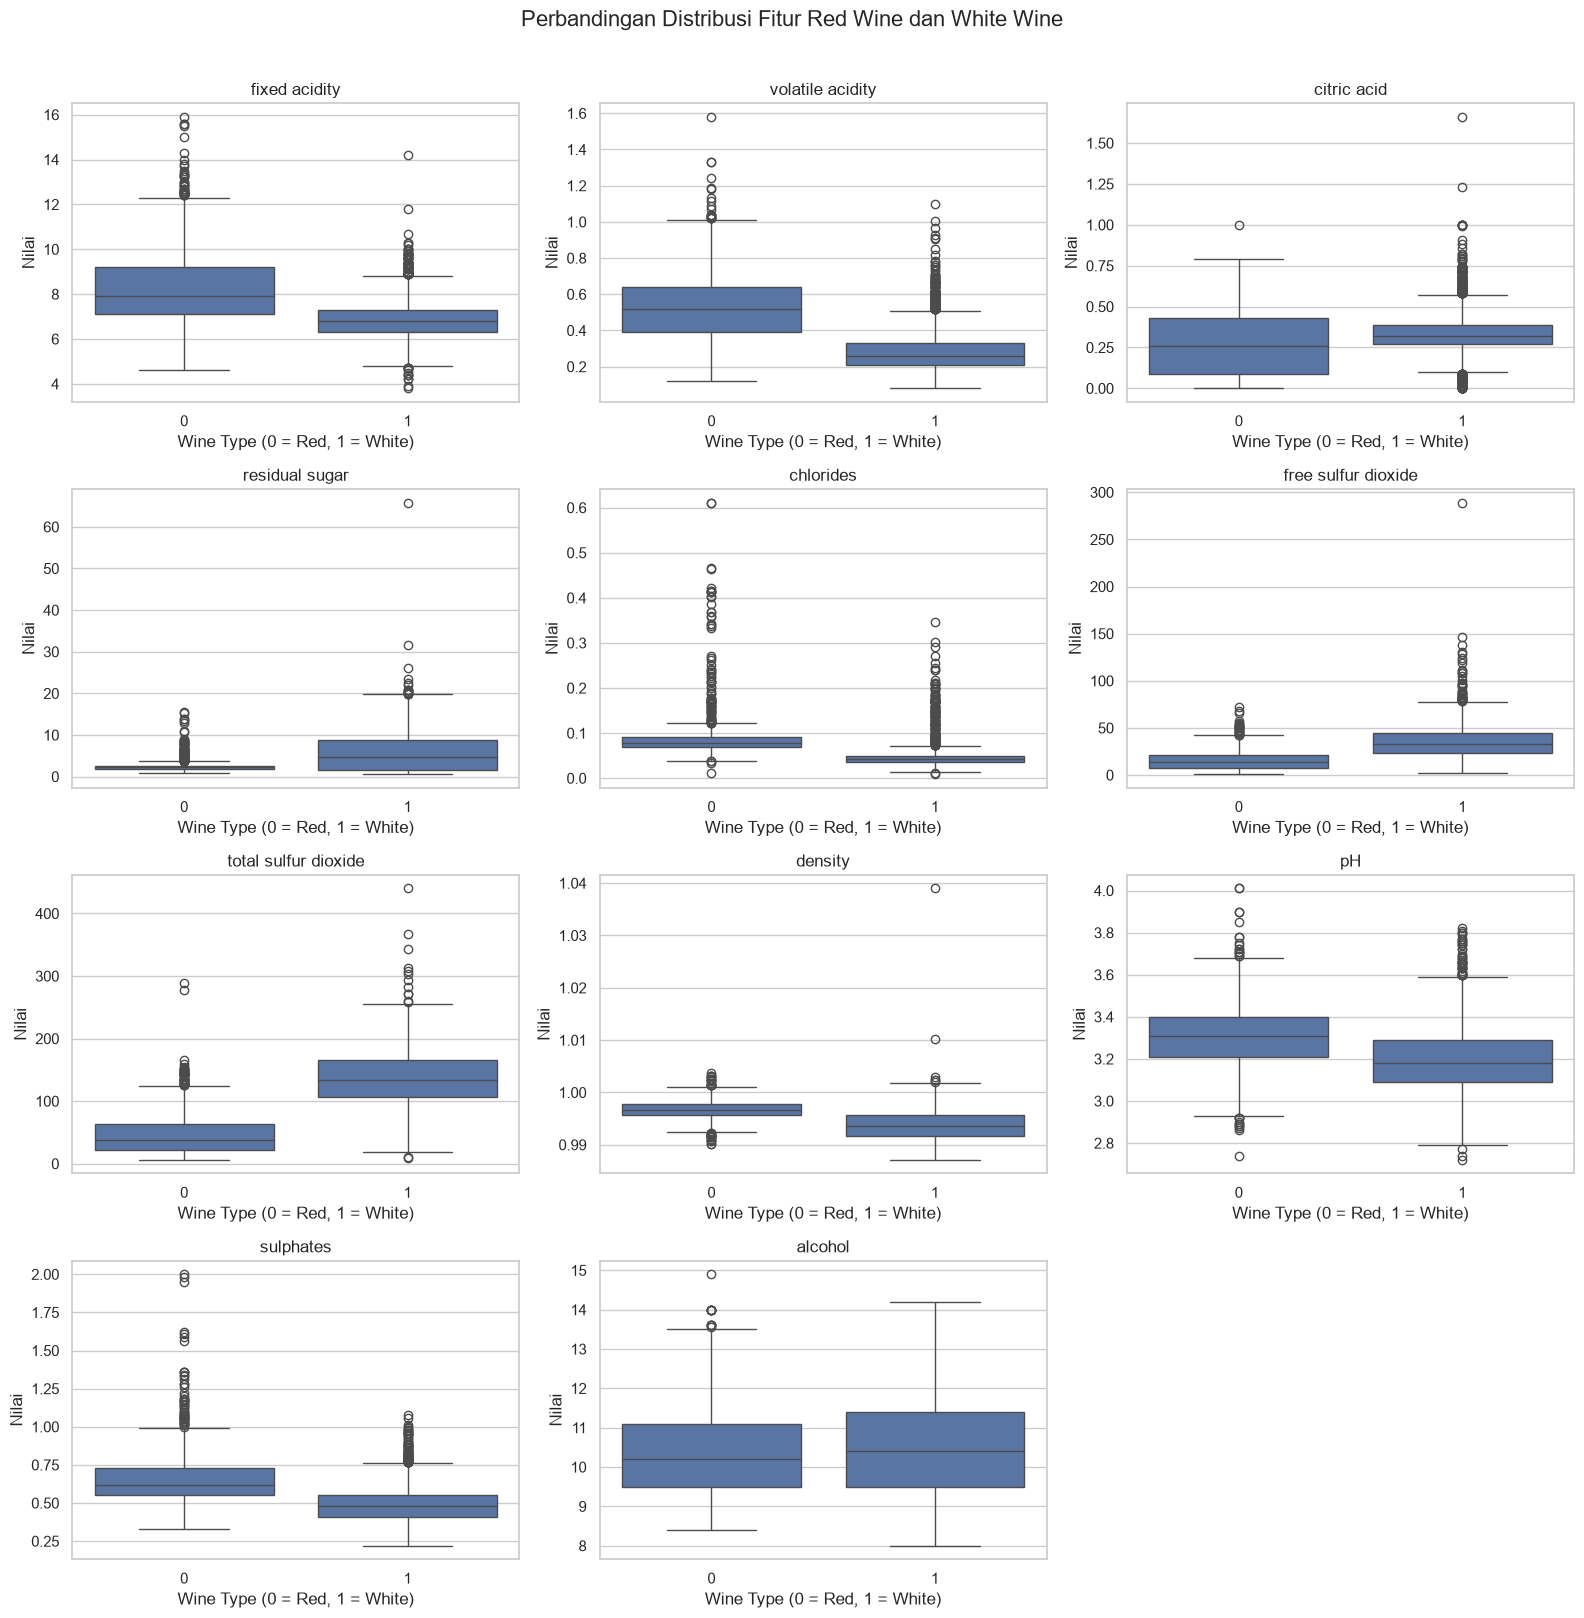

In [6]:
# 6. Perbandingan distribusi fitur berdasarkan jenis wine

feature_cols = [
    col for col in df.columns
    if col not in ["quality", "wine_type"]
]

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(
        data=df,
        x="wine_type",
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("Wine Type (0 = Red, 1 = White)")
    axes[i].set_ylabel("Nilai")

# Sembunyikan subplot yang tidak digunakan
for j in range(len(feature_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Perbandingan Distribusi Fitur Red Wine dan White Wine",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

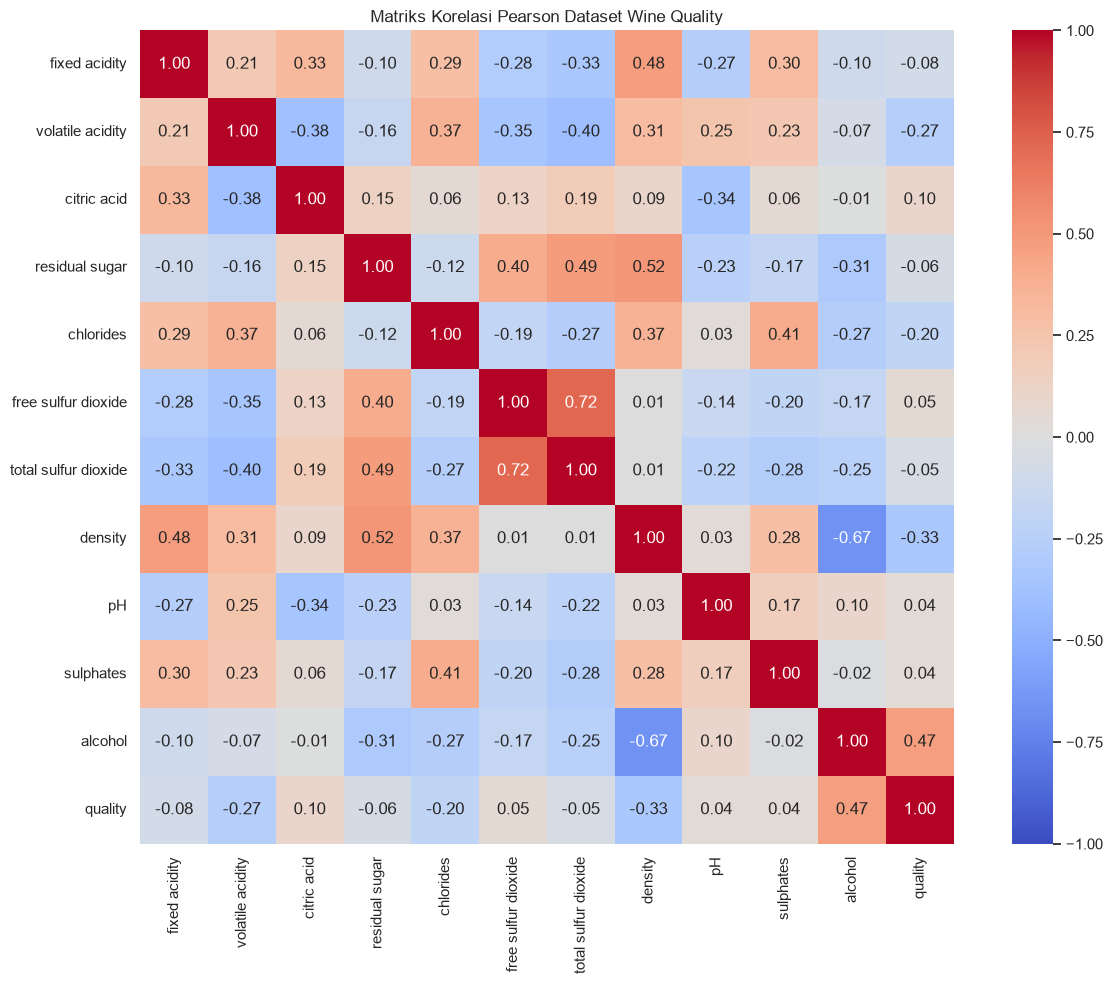

In [7]:
# 7. Analisis korelasi antarvariabel

correlation_cols = [
    col for col in df.columns
    if col != "wine_type"
]

correlation_matrix = df[correlation_cols].corr(
    method="pearson"
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Matriks Korelasi Pearson Dataset Wine Quality")
plt.tight_layout()
plt.show()

,korelasi_dengan_quality
alcohol,0.469
citric acid,0.098
free sulfur dioxide,0.054
sulphates,0.042
pH,0.040
total sulfur dioxide,-0.050
residual sugar,-0.057
fixed acidity,-0.080
chlorides,-0.202
volatile acidity,-0.265


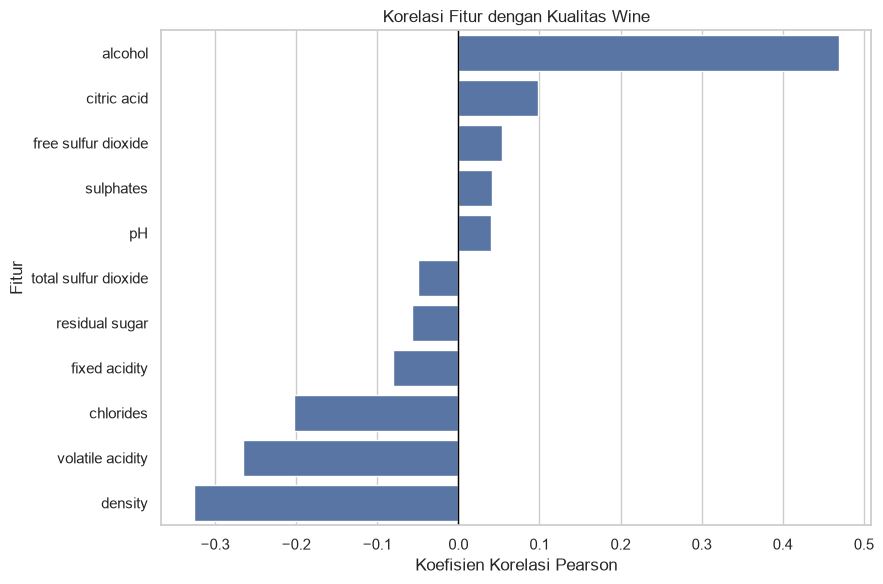

In [8]:
# 8. Korelasi fitur terhadap quality

quality_correlation = (
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

display(
    quality_correlation
    .to_frame("korelasi_dengan_quality")
    .round(3)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=quality_correlation.values,
    y=quality_correlation.index
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Korelasi Fitur dengan Kualitas Wine")
plt.xlabel("Koefisien Korelasi Pearson")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

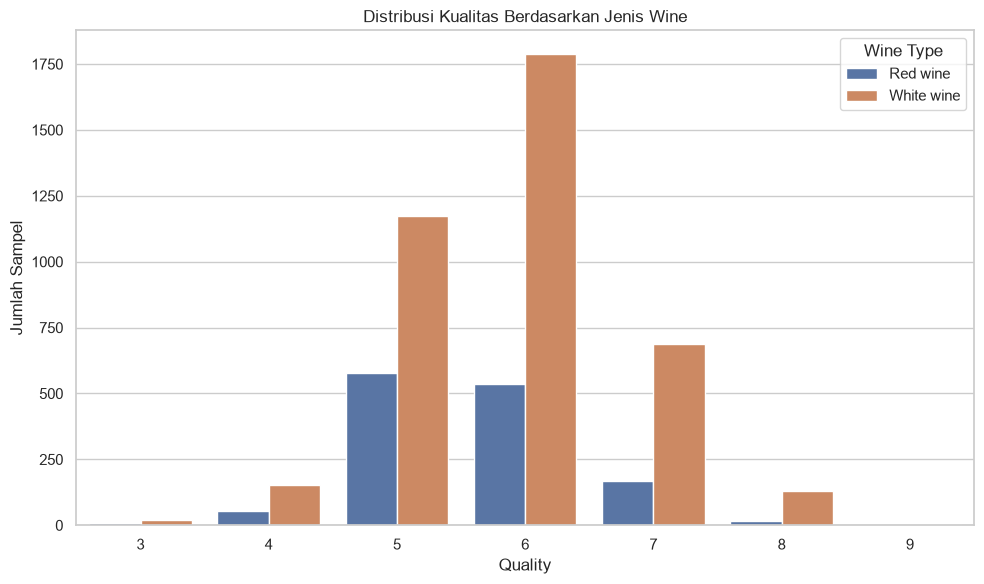

In [9]:
# 9. Distribusi quality berdasarkan jenis wine

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="quality",
    hue="wine_type"
)

plt.title("Distribusi Kualitas Berdasarkan Jenis Wine")
plt.xlabel("Quality")
plt.ylabel("Jumlah Sampel")
plt.legend(
    title="Wine Type",
    labels=["Red wine", "White wine"]
)

plt.tight_layout()
plt.show()

In [10]:
# 10. Persentase kualitas dalam setiap jenis wine

quality_percentage = pd.crosstab(
    df["quality"],
    df["wine_type"],
    normalize="columns"
) * 100

quality_percentage = quality_percentage.rename(
    columns={
        0: "Red wine (%)",
        1: "White wine (%)"
    }
)

display(quality_percentage.round(2))

wine_type,Red wine (%),White wine (%)
quality,,
3,0.74,0.50
4,3.90,3.86
5,42.46,29.66
6,39.37,45.14
7,12.29,17.39
8,1.25,3.31
9,0.00,0.13


## Kesimpulan Exploratory Data Analysis (EDA)

Berdasarkan hasil Exploratory Data Analysis (EDA) terhadap dataset Wine Quality yang telah dibersihkan, diperoleh beberapa temuan utama.

1. **Karakteristik dataset.** Dataset terdiri dari 5.320 sampel dan 13 kolom, yang mencakup 11 fitur fisikokimia, satu variabel kualitas wine (`quality`), dan satu variabel jenis wine (`wine_type`).

2. **Distribusi kualitas.** Sampel paling banyak berada pada kualitas 6 sebanyak 2.323 sampel, diikuti kualitas 5 sebanyak 1.752 sampel. Sebaliknya, kualitas 9 hanya memiliki 5 sampel. Hal ini menunjukkan bahwa distribusi kelas kualitas tidak seimbang.

3. **Perbedaan karakteristik jenis wine.** White wine memiliki rata-rata `total sulfur dioxide`, `free sulfur dioxide`, dan `residual sugar` yang lebih tinggi dibandingkan red wine. Sementara itu, red wine memiliki rata-rata `fixed acidity`, `volatile acidity`, dan `sulphates` yang lebih tinggi.

4. **Hubungan fitur dengan kualitas.** Berdasarkan korelasi Pearson, `alcohol` memiliki korelasi positif terbesar terhadap `quality`, yaitu 0,469. Sementara itu, `density` memiliki korelasi negatif terbesar, yaitu −0,326. Hasil ini menunjukkan hubungan linear, bukan hubungan sebab-akibat.

5. **Perbedaan distribusi kualitas.** Red wine memiliki proporsi kualitas 5 yang lebih tinggi, sedangkan white wine memiliki proporsi kualitas 6, 7, dan 8 yang lebih tinggi. Distribusi kedua jenis wine menunjukkan pola yang berbeda.

Secara keseluruhan, hasil EDA memberikan gambaran mengenai distribusi data, perbedaan karakteristik fisikokimia, dan hubungan antarvariabel. Temuan ini menjadi dasar untuk menentukan tahapan persiapan data dan pemilihan model machine learning pada analisis selanjutnya.